In [1]:
import tensorflow as tf
print(tf.__version__)

2.21.0


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from PIL import Image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras import layers, models
from tensorflow.keras.models import Model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, BatchNormalization, Activation
from tensorflow.keras.layers import MaxPooling2D, GlobalAveragePooling2D
from tensorflow.keras.layers import Dense, Dropout

In [3]:
import random
random.seed(0)
import numpy as np
np.random.seed(0)
import tensorflow as tf
tf.random.set_seed(0)

In [4]:
# dataset paths
train_df = r"C:\Users\Niharika rawat\OneDrive\Desktop\dataset\chest_xray\train"
test_df = r"C:\Users\Niharika rawat\OneDrive\Desktop\dataset\chest_xray\test"
val_df = r"C:\Users\Niharika rawat\OneDrive\Desktop\dataset\chest_xray\val"

# verify dataset structure
print("Train classes:", os.listdir(train_df))
print("Test classes:", os.listdir(test_df))
print("Validation classes:", os.listdir(val_df))

Train classes: ['NORMAL', 'PNEUMONIA']
Test classes: ['NORMAL', 'PNEUMONIA']
Validation classes: ['NORMAL', 'PNEUMONIA']


In [5]:
path = r'C:\Users\Niharika rawat\OneDrive\Desktop\dataset\chest_xray'
image_path_dict = {}  # Create image path dictionary

for split in ['train', 'test', 'val']:
    split_path = os.path.join(path, split)

    for root, dirs, files in os.walk(split_path):
        for f in files:
            if f.lower().endswith('.jpeg'):
                full_path = os.path.join(root, f)
                image_path_dict[f] = full_path

print("Total images:",len(image_path_dict))

Total images: 5856


In [6]:
pneu_df = pd.DataFrame(list(image_path_dict.items()),columns=['image_name', 'image_path'])

pneu_df.head()
pneu_df.shape

(5856, 2)

In [7]:
pneu_df['image_path'].iloc[0]

'C:\\Users\\Niharika rawat\\OneDrive\\Desktop\\dataset\\chest_xray\\train\\NORMAL\\IM-0115-0001.jpeg'

In [8]:
print("Rows:", len(pneu_df))
print("Unique paths:", pneu_df['image_path'].nunique())
print("Duplicate paths:", pneu_df['image_path'].duplicated().sum())

Rows: 5856
Unique paths: 5856
Duplicate paths: 0


In [9]:
print(pneu_df.columns)

Index(['image_name', 'image_path'], dtype='object')


In [10]:
pneu_df

,image_name,image_path
0,IM-0115-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...
1,IM-0117-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...
2,IM-0119-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...
3,IM-0122-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...
4,IM-0125-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...
...,...,...
5851,person1949_bacteria_4880.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...
5852,person1950_bacteria_4881.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...
5853,person1951_bacteria_4882.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...
5854,person1952_bacteria_4883.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...


In [11]:
pneu_df['label'] = pneu_df['image_path'].apply(lambda x:1 if 'PNEUMONIA' in x else 0)  #labeling

In [12]:
pneu_df['label'].value_counts()

label
1    4273
0    1583
Name: count, dtype: int64

In [13]:
pneu_df.tail()

,image_name,image_path,label
5851,person1949_bacteria_4880.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
5852,person1950_bacteria_4881.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
5853,person1951_bacteria_4882.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
5854,person1952_bacteria_4883.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
5855,person1954_bacteria_4886.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1


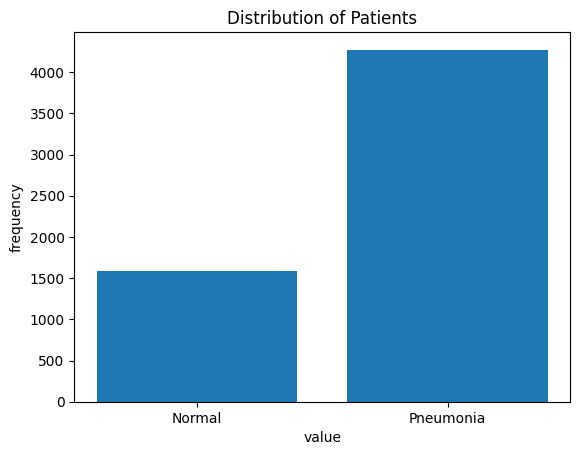

In [14]:
data = pneu_df['label'].value_counts()

plt.bar(data.index, data.values)

plt.xlabel("value")
plt.ylabel("frequency")
plt.title("Distribution of Patients")
plt.xticks([0, 1], ["Normal", "Pneumonia"])
plt.show()

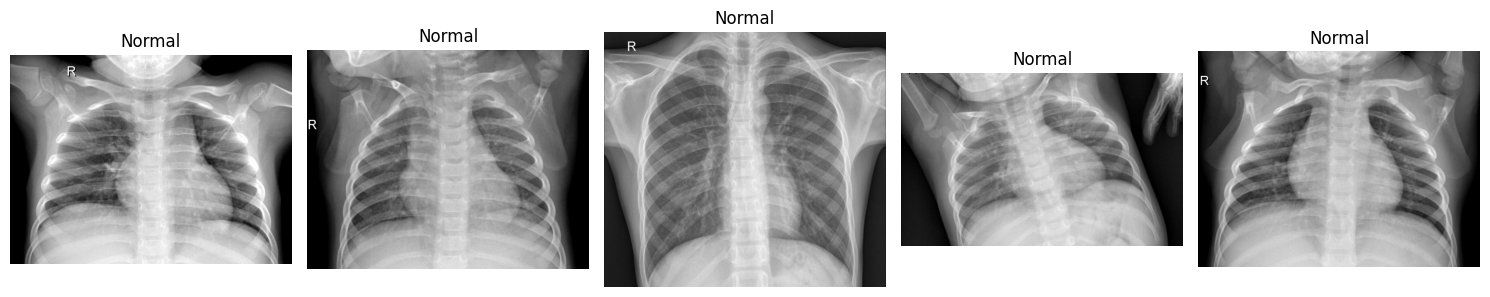

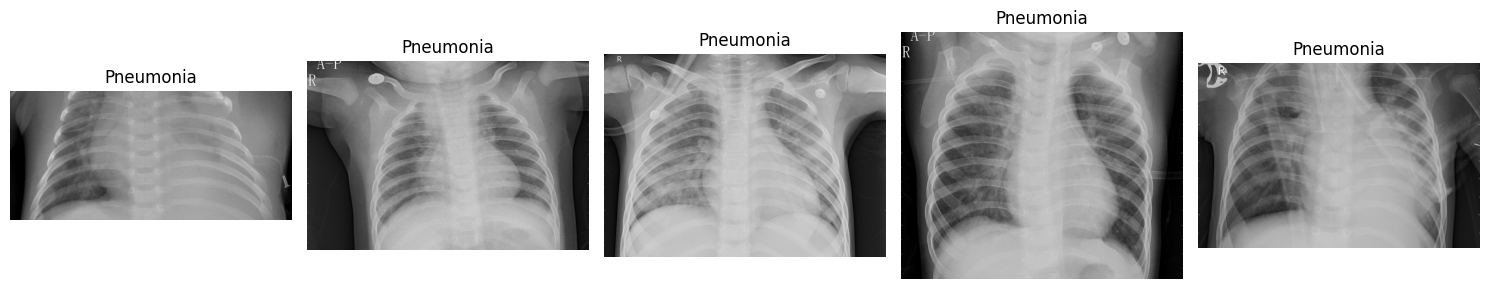

In [15]:
normal_images = pneu_df[pneu_df['label']==0]['image_path'].sample(5, random_state=42)
pneumonia_images = pneu_df[pneu_df['label']==1]['image_path'].sample(5, random_state=42)

plt.figure(figsize=(15, 5))
for i, img_path in enumerate(normal_images):
    img = Image.open(img_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.title('Normal')

plt.tight_layout()
plt.show()


plt.figure(figsize=(15, 5))
for i, img_path in enumerate(pneumonia_images):
    img = Image.open(img_path)

    plt.subplot(1, 5, i + 1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.title('Pneumonia')

plt.tight_layout()
plt.show()

In [16]:
pneu_df.isnull().sum()

image_name    0
image_path    0
label         0
dtype: int64

In [17]:
print("Duplicate Image Names:",pneu_df['image_name'].duplicated().sum())
print("Duplicate Image Path:",pneu_df['image_path'].duplicated().sum())

Duplicate Image Names: 0
Duplicate Image Path: 0


In [18]:
corrupted = []

for path in pneu_df['image_path']:

    try:
        img = Image.open(path)
        img.verify()

    except Exception:
        corrupted.append(path)

print("Corrupted images:", len(corrupted))

Corrupted images: 0


In [19]:
corrupted = []

for path in pneu_df['image_path']:

    try:
        img = Image.open(path)
        img.verify()

    except Exception:
        corrupted.append(path)

print("Corrupted images:", len(corrupted))

Corrupted images: 0


In [20]:
train_df,temp_df = train_test_split(pneu_df,test_size = 0.2,random_state = 42,stratify = pneu_df['label'])

val_df,test_df = train_test_split(temp_df, test_size = 0.5,random_state = 42,stratify = temp_df['label'])

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 4684
Validation: 586
Test: 586


In [21]:
pneu_df

,image_name,image_path,label
0,IM-0115-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,0
1,IM-0117-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,0
2,IM-0119-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,0
3,IM-0122-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,0
4,IM-0125-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,0
...,...,...,...
5851,person1949_bacteria_4880.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
5852,person1950_bacteria_4881.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
5853,person1951_bacteria_4882.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
5854,person1952_bacteria_4883.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1


In [22]:
import PIL.ImageOps as ImageOps 

def processed_image(image_path):
    img=Image.open(image_path)
    img=img.convert('L')
    img = ImageOps.pad(img,(224, 224),color=0,centering=(0.5, 0.5))
    img=np.array(img)
    img=img/255.0
    img = img[..., np.newaxis]
    return img

In [23]:
sample_img = processed_image(train_df.iloc[0]['image_path'])

print(sample_img.shape)
print(sample_img.min(), sample_img.max())

(224, 224, 1)
0.0 0.8274509803921568


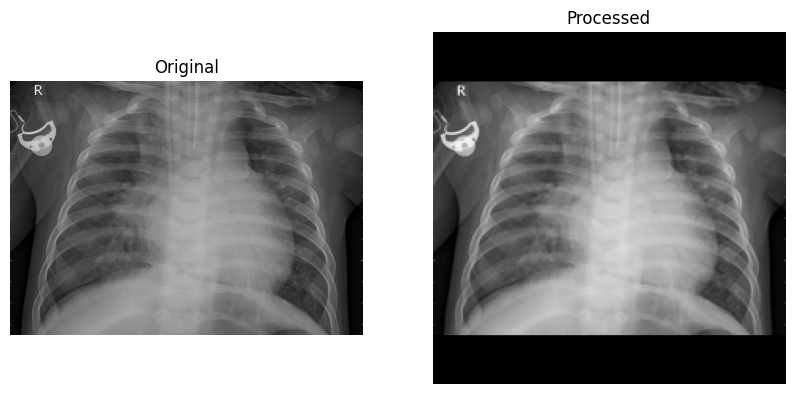

In [24]:
img_path = train_df.iloc[0]['image_path']

original = Image.open(img_path)
processed = processed_image(img_path)

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(original, cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(processed, cmap='gray')
plt.title("Processed")
plt.axis('off')

plt.show()

In [25]:
train_df

,image_name,image_path,label
5786,person80_bacteria_391.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
1427,person1051_virus_1750.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
4746,person734_bacteria_2637.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
3695,person410_bacteria_1825.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
1987,person1320_bacteria_3347.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
...,...,...,...
3896,person462_bacteria_1968.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
989,NORMAL2-IM-0944-0001.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,0
3554,person371_bacteria_1701.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1
2472,person1518_virus_2645.jpeg,C:\Users\Niharika rawat\OneDrive\Desktop\datas...,1


In [26]:
#training dataset
x_train = np.array([processed_image(path)
                    for path in train_df['image_path']])
y_train = train_df['label'].values

#validation dataset
x_val = np.array([processed_image(path)
                    for path in val_df['image_path']])
y_val = val_df['label'].values

#testing dataset
x_test = np.array([processed_image(path)
                    for path in test_df['image_path']])
y_test = test_df['label'].values


print("x_train:", x_train.shape)
print("y_train:", y_train.shape)

print("x_val:", x_val.shape)
print("y_val:", y_val.shape)

print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

x_train: (4684, 224, 224, 1)
y_train: (4684,)
x_val: (586, 224, 224, 1)
y_val: (586,)
x_test: (586, 224, 224, 1)
y_test: (586,)


In [27]:
print(np.unique(y_train))
print(np.unique(y_val))
print(np.unique(y_test))

[0 1]
[0 1]
[0 1]


In [28]:
sample = processed_image(train_df.iloc[0]['image_path'])
print(sample.shape)

(224, 224, 1)


In [29]:
y_train

array([1, 1, 1, ..., 1, 1, 1], shape=(4684,))

In [30]:
train_datagen = ImageDataGenerator(rotation_range = 10,
                                  zoom_range = 0.1,
                                  horizontal_flip = True,
                                  width_shift_range = 0.05,
                                  height_shift_range = 0.05)

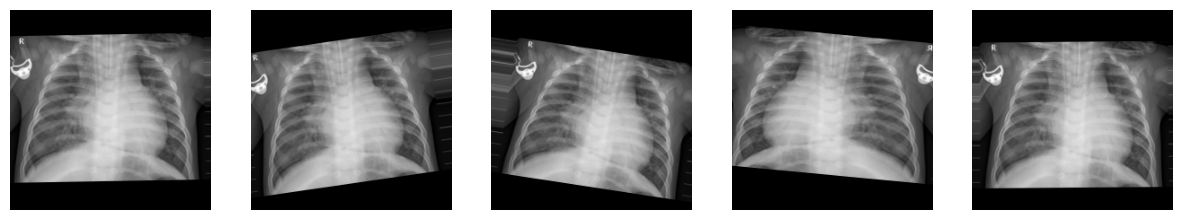

In [31]:
sample = x_train[0].reshape(1,224,224,1)
aug_iter = train_datagen.flow(sample, batch_size=1)
plt.figure(figsize=(15,5))

for i in range(5):
    aug_img = next(aug_iter)[0]
    plt.subplot(1,5,i+1)
    plt.imshow(aug_img.squeeze(), cmap='gray')
    plt.axis('off')

plt.show()

In [32]:
x_train_rgb = np.repeat(x_train, 3, axis=-1)
x_val_rgb   = np.repeat(x_val, 3, axis=-1)
x_test_rgb  = np.repeat(x_test, 3, axis=-1)

print(x_train_rgb.shape)

(4684, 224, 224, 3)


In [33]:
train_generator = train_datagen.flow(x_train_rgb,y_train,batch_size=32,shuffle=True)
val_generator = ImageDataGenerator().flow(x_val_rgb,y_val,batch_size=32)
test_generator = ImageDataGenerator().flow(x_test_rgb,y_test,batch_size=32,shuffle=False)

In [34]:
print(x_train.shape)
print(x_train_rgb.shape if 'x_train_rgb' in globals() else "Not created")

(4684, 224, 224, 1)
(4684, 224, 224, 3)


In [35]:
base_model = DenseNet121(weights='imagenet',
                         include_top=False,
                         input_shape=(224,224,3))  #loading densenet

base_model.trainable = True    #freezing pretrained layers

print(len(base_model.layers))
for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers[-10:]:
    print(layer.name, layer.trainable)
    
x = base_model.output           #adding classification head
x = GlobalAveragePooling2D()(x)

x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

outputs = Dense(1, activation='sigmoid')(x)

model = Model(inputs=base_model.input,
              outputs=outputs)
model.summary()

427
conv5_block15_concat True
conv5_block16_0_bn True
conv5_block16_0_relu True
conv5_block16_1_conv True
conv5_block16_1_bn True
conv5_block16_1_relu True
conv5_block16_2_conv True
conv5_block16_concat True
bn True
relu True


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 224, 224, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ zero_padding2d                │ (None, 230, 230, 3)       │               0 │ input_layer[0][0]          │
│ (ZeroPadding2D)               │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_conv (Conv2D)           │ (None, 112, 112, 64)      │           9,408 │ zero_padding2d[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_bn (BatchNormalization) │ (None, 112, 112, 64)      │             256 │ conv1_conv[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1_relu (Activation)       │ (None, 112, 112, 64)      │               0 │ conv1_bn[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ zero_padding2d_1              │ (None, 114, 114, 64)      │               0 │ conv1_relu[0][0]           │
│ (ZeroPadding2D)               │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pool1 (MaxPooling2D)          │ (None, 56, 56, 64)        │               0 │ zero_padding2d_1[0][0]     │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_0_bn             │ (None, 56, 56, 64)        │             256 │ pool1[0][0]                │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_0_relu           │ (None, 56, 56, 64)        │               0 │ conv2_block1_0_bn[0][0]    │
│ (Activation)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_conv (Conv2D)  │ (None, 56, 56, 128)       │           8,192 │ conv2_block1_0_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_bn             │ (None, 56, 56, 128)       │             512 │ conv2_block1_1_conv[0][0]  │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_1_relu           │ (None, 56, 56, 128)       │               0 │ conv2_block1_1_bn[0][0]    │
│ (Activation)                  │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_2_conv (Conv2D)  │ (None, 56, 56, 32)        │          36,864 │ conv2_block1_1_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv2_block1_concat           │ (None, 56, 56, 96)        │               0 │ pool1[0][0],               │
│ (Concatenate)                 │                           │               

 Total params: 7,300,161 (27.85 MB)

 Trainable params: 904,065 (3.45 MB)

 Non-trainable params: 6,396,096 (24.40 MB)

In [36]:
from tensorflow.keras.metrics import Precision,Recall,AUC
from tensorflow.keras.optimizers import Adam

model.compile(optimizer = Adam(1e-4),
             loss = 'binary_crossentropy',
             metrics=['accuracy',Precision(name='precision'),Recall(name='recall'),AUC(name='auc')])

In [37]:
import tensorflow as tf

print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.21.0
[]


In [38]:
from sklearn.utils.class_weight import compute_class_weight

weights = compute_class_weight(class_weight='balanced',
                              classes=np.unique(train_df['label']),
                              y=train_df['label'])

class_weights = {0:weights[0],
                 1:weights[1]}

In [39]:
from tensorflow.keras.callbacks import EarlyStopping,ReduceLROnPlateau,ModelCheckpoint

early_stopping = EarlyStopping(monitor='val_loss',
                              patience = 3,
                              restore_best_weights = True)
reduce_lr=ReduceLROnPlateau(monitor='val_loss',
                            factor=0.2,
                            patience=2,
                            min_lr=1e-6,
                            verbose=1)
checkpoint=ModelCheckpoint('best_densenet.keras',
                           monitor='val_loss',
                           save_best_only=True,
                           verbose=1)

history = model.fit(train_generator,
                    validation_data=val_generator,
                    epochs=20,
                   class_weight = class_weights,
                   callbacks=[early_stopping,reduce_lr,checkpoint])

Epoch 1/20
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8177 - auc: 0.9005 - loss: 0.3752 - precision: 0.9234 - recall: 0.8193
Epoch 1: val_loss improved from None to 0.22239, saving model to best_densenet.keras
147/147 ━━━━━━━━━━━━━━━━━━━━ 461s 3s/step - accuracy: 0.8792 - auc: 0.9533 - loss: 0.2780 - precision: 0.9541 - recall: 0.8765 - val_accuracy: 0.9061 - val_auc: 0.9886 - val_loss: 0.2224 - val_precision: 0.9895 - val_recall: 0.8806 - learning_rate: 1.0000e-04
Epoch 2/20
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.9385 - auc: 0.9835 - loss: 0.1602 - precision: 0.9771 - recall: 0.9378
Epoch 2: val_loss improved from 0.22239 to 0.15616, saving model to best_densenet.keras
147/147 ━━━━━━━━━━━━━━━━━━━━ 435s 3s/step - accuracy: 0.9351 - auc: 0.9823 - loss: 0.1678 - precision: 0.9744 - recall: 0.9356 - val_accuracy: 0.9386 - val_auc: 0.9897 - val_loss: 0.1562 - val_precision: 0.9827 - val_recall: 0.9321 - learning_rate: 1.0000e-04
Epoch 3/20
147/147 ━━━━━━━━━━━━━━━━

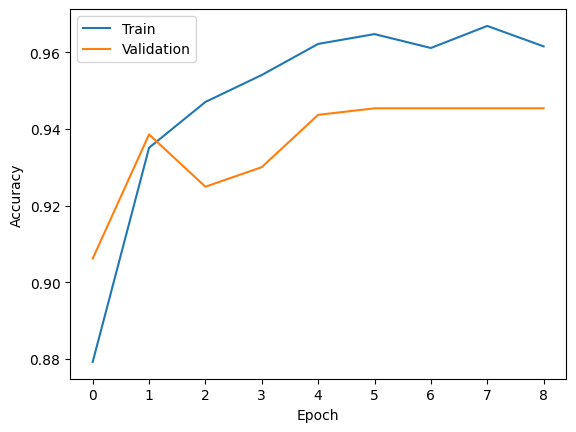

In [40]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig("accuracy_curve.png", dpi=300, bbox_inches="tight")
plt.show()

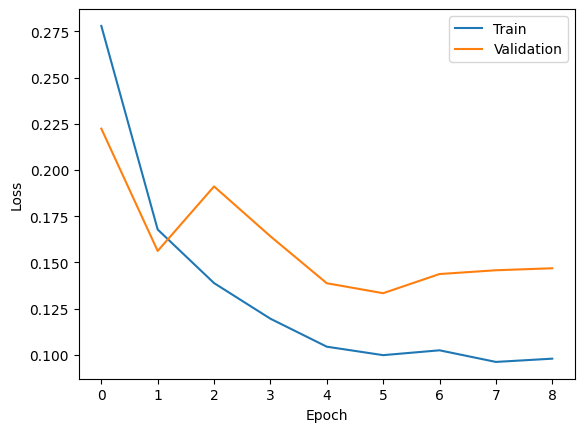

In [41]:
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.savefig("loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

In [42]:
model.load_weights("best_densenet.keras")

In [43]:
from tensorflow.keras.models import load_model

best_model = load_model("best_densenet.keras")

In [44]:
test_results = best_model.evaluate(test_generator)

19/19 ━━━━━━━━━━━━━━━━━━━━ 95s 3s/step - accuracy: 0.9556 - auc: 0.9852 - loss: 0.1422 - precision: 0.9855 - recall: 0.9533


In [45]:
from sklearn.metrics import confusion_matrix

y_true = y_test
y_prob = best_model.predict(test_generator)
y_pred = (y_prob > 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred)

19/19 ━━━━━━━━━━━━━━━━━━━━ 89s 4s/step


In [86]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

y_prob = best_model.predict(test_generator)

y_pred = (y_prob > 0.5).astype(int).flatten()

y_true = y_test

print("Precision:", precision_score(y_true, y_pred))
print("Recall:", recall_score(y_true, y_pred))
print("F1 Score:", f1_score(y_true, y_pred))
print("ROC-AUC:", roc_auc_score(y_true, y_prob))

print("\nClassification Report\n")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["NORMAL", "PNEUMONIA"]
    )
)

print("\nConfusion Matrix\n")
print(confusion_matrix(y_true, y_pred))

19/19 ━━━━━━━━━━━━━━━━━━━━ 68s 4s/step
Precision: 0.9855072463768116
Recall: 0.9532710280373832
F1 Score: 0.9691211401425178
ROC-AUC: 0.9875635868922277

Classification Report

              precision    recall  f1-score   support

      NORMAL       0.88      0.96      0.92       158
   PNEUMONIA       0.99      0.95      0.97       428

    accuracy                           0.96       586
   macro avg       0.93      0.96      0.95       586
weighted avg       0.96      0.96      0.96       586


Confusion Matrix

[[152   6]
 [ 20 408]]


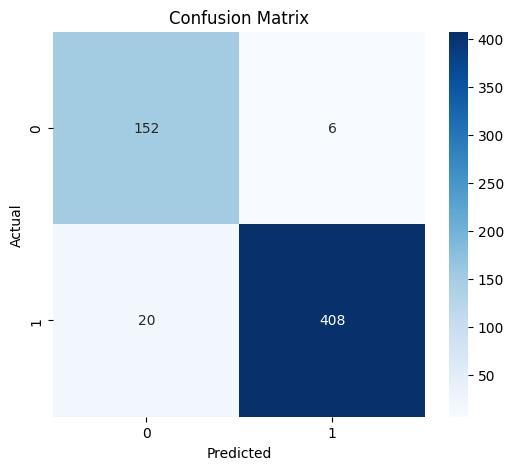

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


In [62]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

auc_score = roc_auc_score(y_test, y_prob)

print("AUC =", auc_score)

AUC = 0.9875635868922277


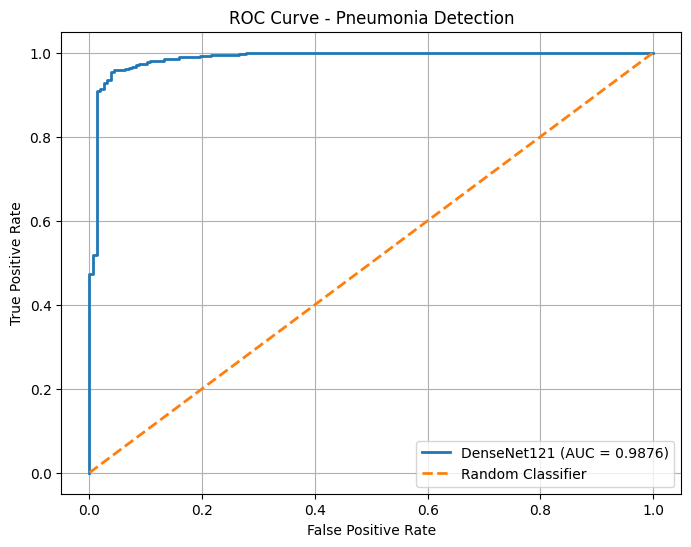

In [63]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.plot(fpr,tpr,linewidth=2,label=f'DenseNet121 (AUC = {auc_score:.4f})')

plt.plot([0,1],[0,1],linestyle='--',linewidth=2,label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Pneumonia Detection')
plt.legend(loc='lower right')
plt.grid(True)

plt.savefig("roc_curve_densenet.png", dpi=300, bbox_inches="tight")
plt.show()

True Label: 0


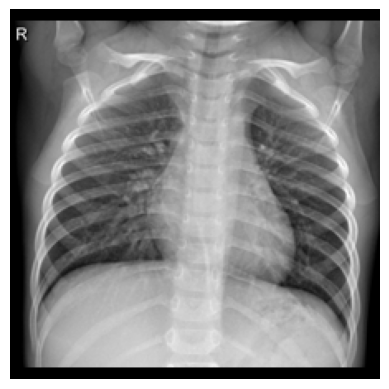

In [64]:
idx = 0

img = x_test_rgb[idx]
label = y_test[idx]

print("True Label:", label)

plt.imshow(img)
plt.axis("off")
plt.show()


In [65]:
img_array = np.expand_dims(img, axis=0)

pred = best_model.predict(img_array)
prob=pred[0][0]

print("Pneumonia Probability:", pred[0][0])
if prob > 0.5:
    print("Prediction: PNEUMONIA")
else:
    print("Prediction: NORMAL")

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 521ms/step
Pneumonia Probability: 0.0005779501
Prediction: NORMAL


In [66]:
for i in range(len(x_test_rgb)):
    
    pred = best_model.predict(np.expand_dims(x_test_rgb[i], axis=0),verbose=0)[0][0]

    if pred > 0.99 and y_test[i] == 1:
        idx = i
        break

print("Selected image:", idx)

Selected image: 3


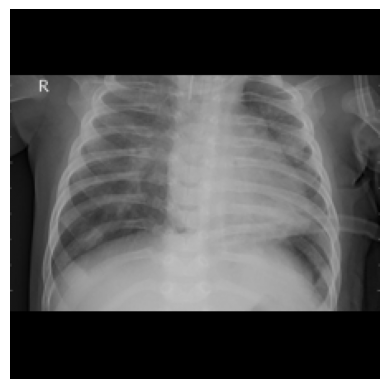

In [67]:
img = x_test_rgb[idx]

plt.imshow(img)
plt.axis("off")
plt.show()

In [68]:
img = x_test_rgb[idx]
img_array = np.expand_dims(img, axis=0)

In [69]:
pred = best_model.predict(img_array)

print("True Label:", y_test[idx])
print("Pneumonia Probability:", pred[0][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 666ms/step
True Label: 1
Pneumonia Probability: 0.99909747


In [70]:
for layer in best_model.layers:
    print(layer.name)

best_model.get_layer("conv5_block16_concat")

input_layer
zero_padding2d
conv1_conv
conv1_bn
conv1_relu
zero_padding2d_1
pool1
conv2_block1_0_bn
conv2_block1_0_relu
conv2_block1_1_conv
conv2_block1_1_bn
conv2_block1_1_relu
conv2_block1_2_conv
conv2_block1_concat
conv2_block2_0_bn
conv2_block2_0_relu
conv2_block2_1_conv
conv2_block2_1_bn
conv2_block2_1_relu
conv2_block2_2_conv
conv2_block2_concat
conv2_block3_0_bn
conv2_block3_0_relu
conv2_block3_1_conv
conv2_block3_1_bn
conv2_block3_1_relu
conv2_block3_2_conv
conv2_block3_concat
conv2_block4_0_bn
conv2_block4_0_relu
conv2_block4_1_conv
conv2_block4_1_bn
conv2_block4_1_relu
conv2_block4_2_conv
conv2_block4_concat
conv2_block5_0_bn
conv2_block5_0_relu
conv2_block5_1_conv
conv2_block5_1_bn
conv2_block5_1_relu
conv2_block5_2_conv
conv2_block5_concat
conv2_block6_0_bn
conv2_block6_0_relu
conv2_block6_1_conv
conv2_block6_1_bn
conv2_block6_1_relu
conv2_block6_2_conv
conv2_block6_concat
pool2_bn
pool2_relu
pool2_conv
pool2_pool
conv3_block1_0_bn
conv3_block1_0_relu
conv3_block1_1_conv
con

<Concatenate name=conv5_block16_concat, built=True>

In [77]:
last_conv_layer_name = "conv5_block14_concat"

In [78]:
import tensorflow as tf
import numpy as np

def make_gradcam_heatmap(img_array,model,last_conv_layer_name):
    grad_model = tf.keras.models.Model(model.inputs,[model.get_layer(last_conv_layer_name).output,model.output])

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, 0]
    grads = tape.gradient(loss,conv_outputs)
    pooled_grads = tf.reduce_mean(grads,axis=(0,1,2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap,0)
    heatmap /= tf.math.reduce_max(heatmap)
    return heatmap.numpy()

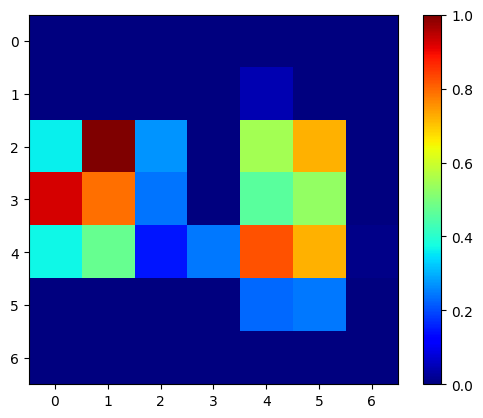

In [79]:
heatmap = make_gradcam_heatmap(img_array,best_model,last_conv_layer_name)
plt.imshow(heatmap,cmap='jet')

plt.colorbar()
plt.show()

In [83]:
%pip install opencv-python

  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Note: you may need to restart the kernel to use updated packages.


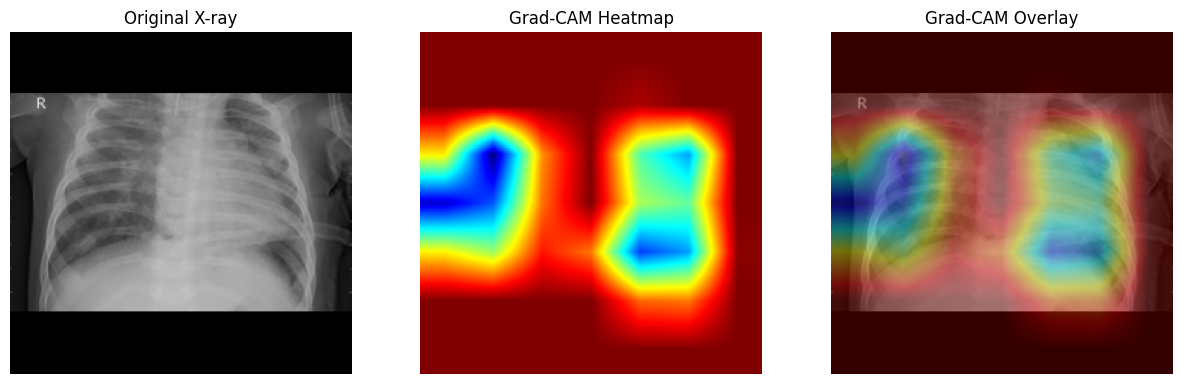

In [84]:
import cv2

heatmap = cv2.resize(heatmap,(224,224))
heatmap = np.uint8(255 * heatmap)
heatmap = cv2.applyColorMap(heatmap,cv2.COLORMAP_JET)
original = (img * 255).astype(np.uint8)
overlay = cv2.addWeighted(original,0.6,heatmap,0.4,0)
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(original)
plt.title("Original X-ray")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(heatmap)
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.show()

In [85]:
best_model.save("best_densenet.keras")